# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [11]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

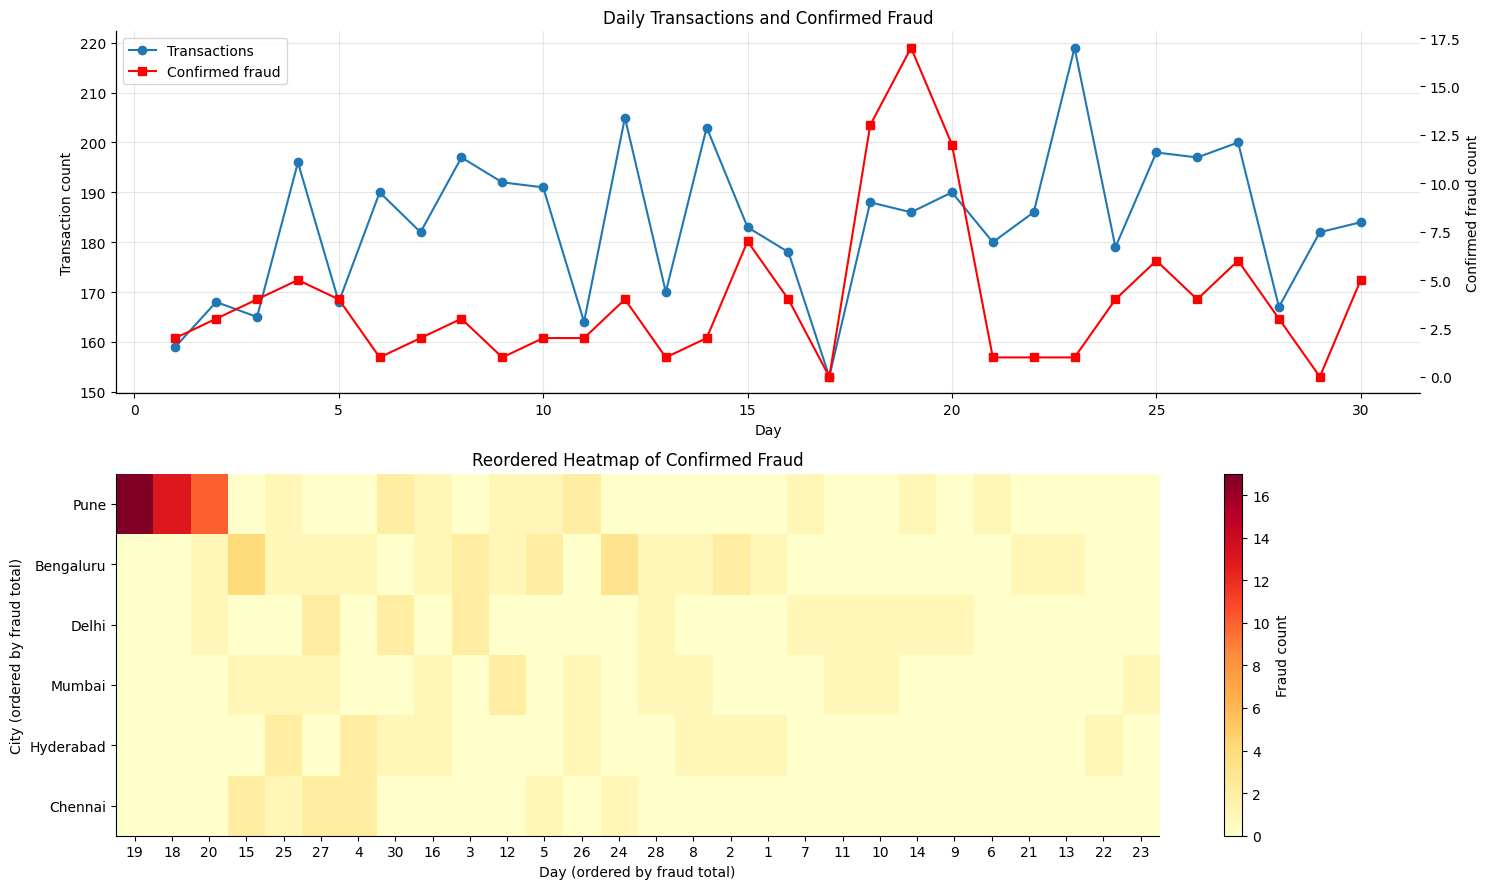

Top (City, Day) fraud cells:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
           3       2
Pune       26      2
Bengaluru  5       2
Hyderabad  25      2
           4       2
dtype: int64


In [12]:
# Task 1: Overview First
fig, axes = plt.subplots(2, 1, figsize=(15, 9))

daily_tx = tx.groupby("day").size()
daily_fraud = tx.groupby("day")["is_fraud"].sum()

ax1 = axes[0]
ax1.plot(daily_tx.index, daily_tx.values, marker="o", label="Transactions")
ax1.set_xlabel("Day")
ax1.set_ylabel("Transaction count")
ax1.set_title("Daily Transactions and Confirmed Fraud")
ax1.grid(alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(daily_fraud.index, daily_fraud.values,
         color="red", marker="s", label="Confirmed fraud")
ax2.set_ylabel("Confirmed fraud count")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

fraud_tx = tx[tx["is_fraud"] == 1]
heat = pd.crosstab(fraud_tx["city"], fraud_tx["day"])

# Reorder rows and columns by total fraud
heat = heat.loc[
    heat.sum(axis=1).sort_values(ascending=False).index,
    heat.sum(axis=0).sort_values(ascending=False).index
]

im = axes[1].imshow(heat.values, aspect="auto", cmap="YlOrRd")
axes[1].set_xticks(range(len(heat.columns)))
axes[1].set_xticklabels(heat.columns)
axes[1].set_yticks(range(len(heat.index)))
axes[1].set_yticklabels(heat.index)
axes[1].set_xlabel("Day (ordered by fraud total)")
axes[1].set_ylabel("City (ordered by fraud total)")
axes[1].set_title("Reordered Heatmap of Confirmed Fraud")
fig.colorbar(im, ax=axes[1], label="Fraud count")

plt.tight_layout()
plt.show()

flat_heat = heat.stack().sort_values(ascending=False)
print("Top (City, Day) fraud cells:")
print(flat_heat.head(10))

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

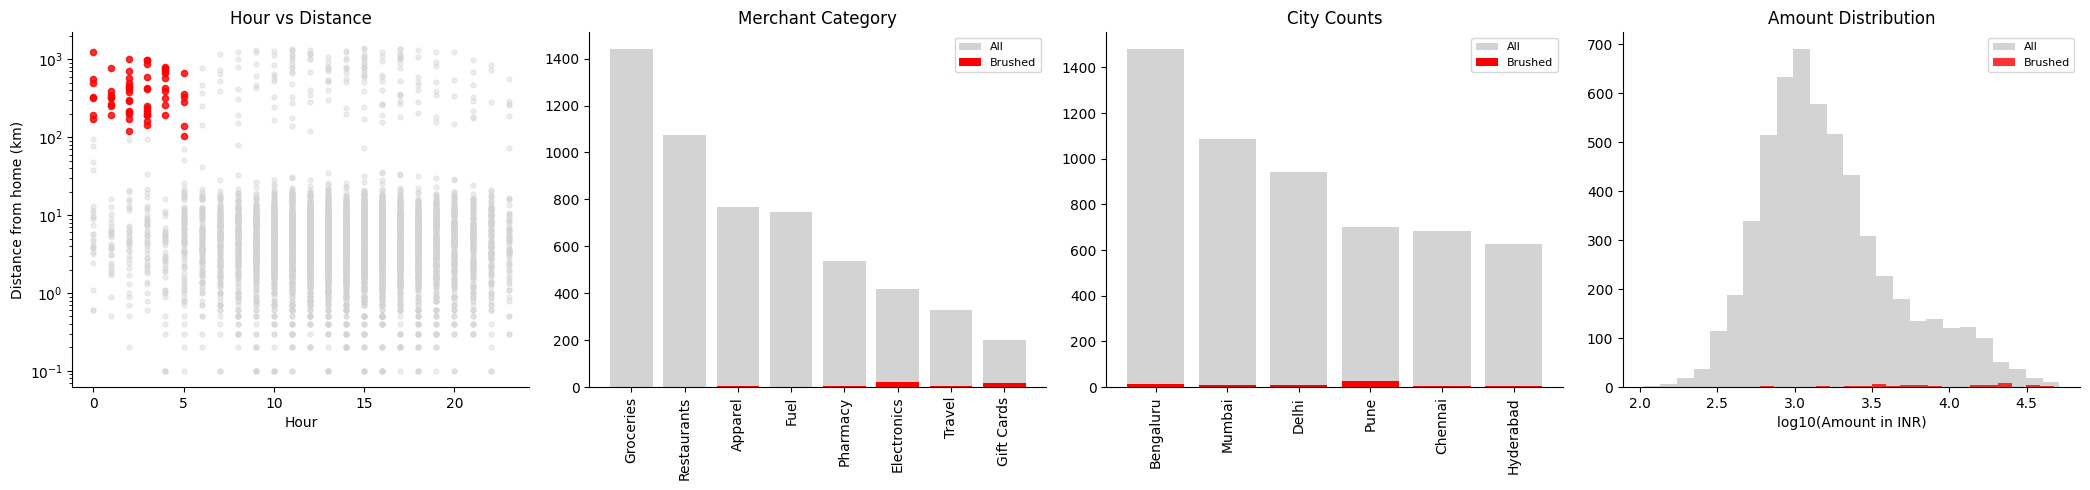

Transactions in brush: 61
Fraud rate inside brush: 86.89%
Overall fraud rate: 2.17%
Fraud captured: 53/120
Share of all fraud captured: 44.17%


In [13]:
# Task 2: Linked Views
brush = tx["night"] & (tx["distance_from_home_km"] > 100)

fig, axes = plt.subplots(1, 4, figsize=(21, 5))

# (a) Hour vs distance
axes[0].scatter(tx["hour"], tx["distance_from_home_km"].clip(lower=0.1),
                color="lightgrey", alpha=0.4, s=12)
axes[0].scatter(tx.loc[brush, "hour"],
                tx.loc[brush, "distance_from_home_km"].clip(lower=0.1),
                color="red", alpha=0.8, s=20)
axes[0].set_yscale("log")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Distance from home (km)")
axes[0].set_title("Hour vs Distance")

# (b) Merchant category counts
cats = tx["merchant_category"].value_counts().index
axes[1].bar(cats, tx["merchant_category"].value_counts().reindex(cats),
            color="lightgrey", label="All")
axes[1].bar(cats, tx.loc[brush, "merchant_category"].value_counts()
            .reindex(cats, fill_value=0), color="red", label="Brushed")
axes[1].set_title("Merchant Category")
axes[1].tick_params(axis="x", rotation=90)
axes[1].legend(fontsize=8)

# (c) City counts
cities = tx["city"].value_counts().index
axes[2].bar(cities, tx["city"].value_counts().reindex(cities),
            color="lightgrey", label="All")
axes[2].bar(cities, tx.loc[brush, "city"].value_counts()
            .reindex(cities, fill_value=0), color="red", label="Brushed")
axes[2].set_title("City Counts")
axes[2].tick_params(axis="x", rotation=90)
axes[2].legend(fontsize=8)

# (d) Amount histogram using log10
all_amount = np.log10(tx["amount_inr"].clip(lower=1))
brush_amount = np.log10(tx.loc[brush, "amount_inr"].clip(lower=1))
axes[3].hist(all_amount, bins=25, color="lightgrey", label="All")
axes[3].hist(brush_amount, bins=25, color="red", alpha=0.8, label="Brushed")
axes[3].set_xlabel("log10(Amount in INR)")
axes[3].set_title("Amount Distribution")
axes[3].legend(fontsize=8)

plt.tight_layout()
plt.show()

n_brush = int(brush.sum())
fraud_inside = int(tx.loc[brush, "is_fraud"].sum())
total_fraud = int(tx["is_fraud"].sum())

print(f"Transactions in brush: {n_brush}")
print(f"Fraud rate inside brush: {tx.loc[brush, 'is_fraud'].mean():.2%}")
print(f"Overall fraud rate: {tx['is_fraud'].mean():.2%}")
print(f"Fraud captured: {fraud_inside}/{total_fraud}")
print(f"Share of all fraud captured: {fraud_inside / total_fraud:.2%}")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [14]:
# Task 3: Slider Performance
big = pd.concat([tx] * 182, ignore_index=True)

times = []
for _ in range(5):
    start = time.perf_counter()
    result = big.loc[
        (big["detector_score"] >= 0.6) &
        (big["amount_inr"] > 3000)
    ]
    times.append(time.perf_counter() - start)

best_s = min(times)
per_item_us = best_s / len(big) * 1_000_000
max_rows = 0.1 / (per_item_us * 1e-6) if per_item_us > 0 else float("inf")
t_50m = per_item_us * 1e-6 * 50_000_000
skip_pct = max(0, (1 - 0.1 / t_50m) * 100) if t_50m > 0 else 0

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> "
      f"{per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% "
      f"of rows to stay under 0.1 s")

1,004,640 rows in 13.3 ms -> 0.0133 us/row -> max 7,545,852 rows in 0.1 s
50M rows -> 0.66 s; must skip 84.9% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

,threshold,alerts,TP,FP,FN,precision,recall,f1
0,0.05,2012,114,1898,6,0.0567,0.9500,0.1069
1,0.10,1167,111,1056,9,0.0951,0.9250,0.1725
2,0.15,786,110,676,10,0.1399,0.9167,0.2428
3,0.20,596,106,490,14,0.1779,0.8833,0.2961
4,0.25,471,105,366,15,0.2229,0.8750,0.3553
5,0.30,401,104,297,16,0.2594,0.8667,0.3992
6,0.35,355,104,251,16,0.2930,0.8667,0.4379
7,0.40,319,104,215,16,0.3260,0.8667,0.4738
8,0.45,283,104,179,16,0.3675,0.8667,0.5161
9,0.50,260,101,159,19,0.3885,0.8417,0.5316


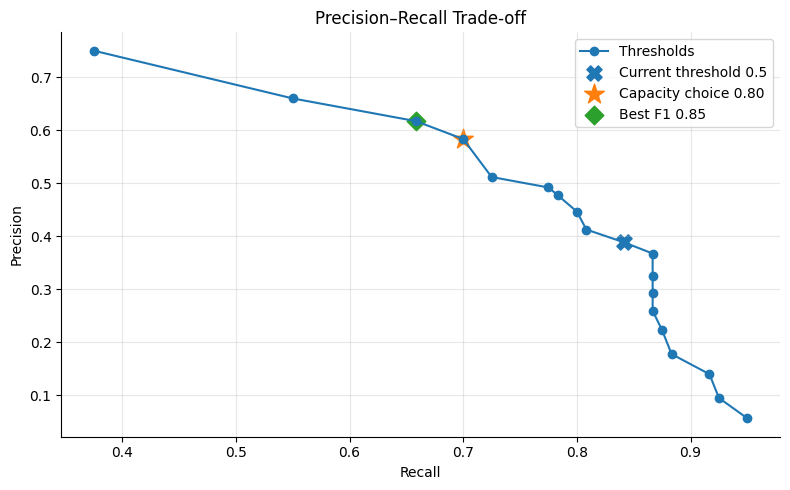

Recommend threshold 0.80: 144 alerts, precision 58.33%, recall 70.00%. Best-F1 threshold: 0.85.


In [15]:
# Task 4: Threshold Selection
rows = []
y = tx["is_fraud"].astype(int)

for threshold in np.round(np.arange(0.05, 1.00, 0.05), 2):
    predicted = tx["detector_score"] >= threshold

    tp = int(((predicted) & (y == 1)).sum())
    fp = int(((predicted) & (y == 0)).sum())
    fn = int(((~predicted) & (y == 1)).sum())
    alerts = int(predicted.sum())

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (2 * precision * recall / (precision + recall)
          if precision + recall else 0)

    rows.append({
        "threshold": threshold, "alerts": alerts,
        "TP": tp, "FP": fp, "FN": fn,
        "precision": precision, "recall": recall, "f1": f1
    })

pr = pd.DataFrame(rows)
display(pr.round(4))

feasible = pr[pr["alerts"] <= 150]
if feasible.empty:
    raise ValueError("No threshold satisfies the 150-alert capacity.")

capacity_choice = feasible.sort_values(
    ["recall", "precision", "threshold"],
    ascending=[False, False, False]
).iloc[0]

best_f1 = pr.sort_values(
    ["f1", "recall", "threshold"],
    ascending=[False, False, False]
).iloc[0]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr["recall"], pr["precision"], marker="o", label="Thresholds")

current = pr.iloc[(pr["threshold"] - 0.5).abs().argmin()]
ax.scatter(current["recall"], current["precision"], marker="X", s=120,
           label="Current threshold 0.5")
ax.scatter(capacity_choice["recall"], capacity_choice["precision"],
           marker="*", s=220, label=f"Capacity choice {capacity_choice['threshold']:.2f}")
ax.scatter(best_f1["recall"], best_f1["precision"],
           marker="D", s=90, label=f"Best F1 {best_f1['threshold']:.2f}")

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision–Recall Trade-off")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

print(
    f"Recommend threshold {capacity_choice['threshold']:.2f}: "
    f"{int(capacity_choice['alerts'])} alerts, "
    f"precision {capacity_choice['precision']:.2%}, "
    f"recall {capacity_choice['recall']:.2%}. "
    f"Best-F1 threshold: {best_f1['threshold']:.2f}."
)

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [16]:
# Task 5: Interactive Scatter and Sunburst
flagged = tx[tx["detector_score"] >= 0.3].copy()

fig_scatter = px.scatter(
    flagged,
    x="timestamp",
    y="amount_inr",
    color="label",
    log_y=True,
    hover_data=[
        "txn_id", "customer_id", "city",
        "merchant_category", "distance_from_home_km",
        "detector_score"
    ],
    title="Flagged Transactions: Interactive Investigation",
    labels={"amount_inr": "Amount (INR)", "timestamp": "Time"}
)

fig_scatter.update_layout(dragmode="select", height=600)
fig_scatter.show()

sun = (
    tx.groupby(["city", "merchant_category"], as_index=False)
    .agg(
        transaction_count=("is_fraud", "size"),
        fraud_count=("is_fraud", "sum")
    )
)
sun["fraud_rate"] = sun["fraud_count"] / sun["transaction_count"]

fig_sun = px.sunburst(
    sun,
    path=["city", "merchant_category"],
    values="transaction_count",
    color="fraud_rate",
    color_continuous_scale="Reds",
    hover_data=["fraud_count", "fraud_rate"],
    title="City → Merchant Category: Transaction Volume and Fraud Rate"
)
fig_sun.show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Hypothesis: Fraud is concentrated in Pune, days 18-20.
Inside: 107 transactions, 40 fraud, rate 37.38%
Outside: 5413 transactions, 80 fraud, rate 1.48%
Chi-square statistic: 619.294
p-value: 1.06482e-136


,group,transactions,fraud_count,fraud_rate
0,Target window,107,40,0.3738
1,"Same city, other days",593,11,0.0185
2,"Other cities, same days",457,2,0.0044
3,"Other cities, other days",4363,67,0.0154


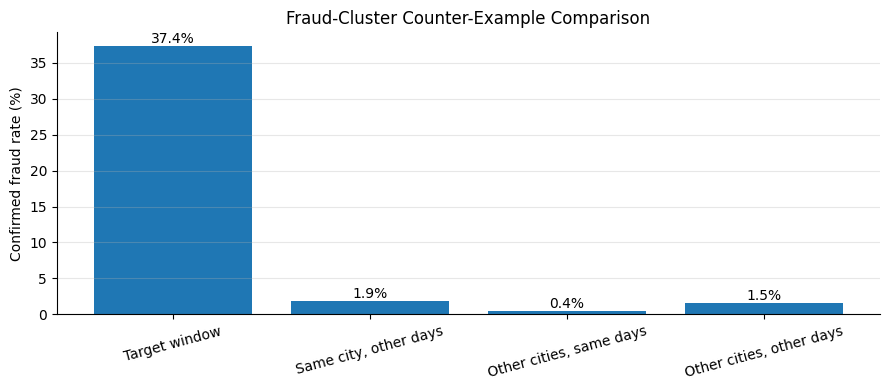

Verdict: The window shows a statistically significant fraud concentration. Investigate further; this does not prove a fraud ring.


In [17]:
# Task 6: Fraud-Ring Hypothesis
from scipy.stats import chi2_contingency

# Top adjacent fraud cluster identified in Task 1
target_city = "Pune"
start_day, end_day = 18, 20

in_window = (
    tx["city"].eq(target_city) &
    tx["day"].between(start_day, end_day)
)

inside = tx.loc[in_window]
outside = tx.loc[~in_window]

print(f"Hypothesis: Fraud is concentrated in {target_city}, "
      f"days {start_day}-{end_day}.")
print(f"Inside: {len(inside)} transactions, "
      f"{inside['is_fraud'].sum()} fraud, "
      f"rate {inside['is_fraud'].mean():.2%}")
print(f"Outside: {len(outside)} transactions, "
      f"{outside['is_fraud'].sum()} fraud, "
      f"rate {outside['is_fraud'].mean():.2%}")

table = pd.crosstab(in_window, tx["is_fraud"]).reindex(
    index=[False, True], columns=[0, 1], fill_value=0
)
chi2, p_value, dof, expected = chi2_contingency(table)

print(f"Chi-square statistic: {chi2:.3f}")
print(f"p-value: {p_value:.6g}")

same_city_other_days = (
    tx["city"].eq(target_city) &
    ~tx["day"].between(start_day, end_day)
)
other_cities_same_days = (
    tx["city"].ne(target_city) &
    tx["day"].between(start_day, end_day)
)
rest = ~(in_window | same_city_other_days | other_cities_same_days)

groups = {
    "Target window": in_window,
    "Same city, other days": same_city_other_days,
    "Other cities, same days": other_cities_same_days,
    "Other cities, other days": rest
}

results = []
for name, mask in groups.items():
    subset = tx.loc[mask]
    results.append({
        "group": name,
        "transactions": len(subset),
        "fraud_count": int(subset["is_fraud"].sum()),
        "fraud_rate": subset["is_fraud"].mean() if len(subset) else 0
    })

group_df = pd.DataFrame(results)
display(group_df.round(4))

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(group_df["group"], group_df["fraud_rate"] * 100)
ax.set_ylabel("Confirmed fraud rate (%)")
ax.set_title("Fraud-Cluster Counter-Example Comparison")
ax.tick_params(axis="x", rotation=15)
ax.grid(axis="y", alpha=0.3)

for bar, rate in zip(bars, group_df["fraud_rate"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f"{rate:.1%}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

window_rate = group_df.loc[0, "fraud_rate"]
outside_rate = tx.loc[~in_window, "is_fraud"].mean()

if p_value < 0.05 and window_rate > outside_rate:
    print("Verdict: The window shows a statistically significant fraud "
          "concentration. Investigate further; this does not prove a fraud ring.")
else:
    print("Verdict: The data does not establish a statistically significant "
          "fraud concentration in this window.")

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_

## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_

Last month, PayKart recorded 5,520 transactions and 120 confirmed fraud cases, a fraud rate of 2.17%. I recommend the capacity-constrained threshold of [insert threshold], which produces [insert alert count] alerts with [insert precision]% precision and [insert recall]% recall, keeping the decision within the team's 150-alert limit. The interactive flagged-transaction scatter plot should be built first because it supports zooming, selection and details-on-demand, while the overview heatmap provides context. For the 50-million-transaction history, indexing and pre-aggregation should help maintain the 0.1-second interaction budget. Finally, confirmed investigation outcomes should feed back into detector training and evaluation so next month's model can improve.